In [2]:
import numpy as np
import pandas as pd

# قراءة الملف المرفوع في Colab
df = pd.read_csv('raw.csv')
print('حجم البيانات (صفوف، أعمدة):', df.shape)
print('\nأسماء الأعمدة وأنواعها:')
print(df.dtypes)

print('\n--- 1. القيم المفقودة ---')
missing = df.isnull().sum()
print(missing[missing > 0])

print('\n--- 2. الصفوف المكررة ---')
print('عدد التكرارات الكاملة:', df.duplicated().sum())
print('عدد معرفات الإعلان id المكررة:', df['id'].duplicated().sum())

print('\n--- 3. فحص السعر (price - Target) ---')
print('عدد الإعلانات بسعر <= 0:', (df['price'] <= 0).sum())
print(df['price'].describe())

print('\n--- 4. فحص الحد الأدنى لليالي (minimum_nights) ---')
print('عدد الإعلانات بـ minimum_nights > 365:', (df['minimum_nights'] > 365).sum())
print(df['minimum_nights'].describe())

حجم البيانات (صفوف، أعمدة): (48895, 16)

أسماء الأعمدة وأنواعها:
id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtype: object

--- 1. القيم المفقودة ---
name                    16
host_name               21
last_review          10052
reviews_per_month    10052
dtype: int64

--- 2. الصفوف المكررة ---
عدد التكرارات الكاملة: 0
عدد معرفات الإعلان id المكررة: 0

--- 3. فحص السع

سجل قرارات التنظيف (Decision Log):

1. المشكلة: أسعار صفرية في عمود الهدف (price <= 0).
- القرار: حذف هذه الصفوف.
- السبب بالرقم: يوجد 11 إعلاناً بسعر 0.0 من أصل 48,895 إعلاناً (والحد الأقصى 10,000).
- الصفوف المتأثرة: 11 صفاً.

2. المشكلة: نقص في reviews_per_month و last_review.
- القرار: تعبئة reviews_per_month بقيمة 0 (عدم وجود مراجعات شهرية).
- السبب بالرقم: يوجد 10,052 قيمة مفقودة في كلٍ من العمودين (حوالي 20.56% من 48,895 صفاً).
- الصفوف المتأثرة: 10,052 صفاً.

3. المشكلة: نقص في name و host_name.
- القرار: تعبئة القيم الناقصة بقيمة نصية (غير محدد) دون حذف الصفوف.
- السبب بالرقم: يوجد 16 نقصاً في name و 21 نقصاً في host_name من أصل 48,895 صفاً.
- الصفوف المتأثرة: 16 صفاً لـ name و 21 صفاً لـ host_name.

4. المشكلة: قيم مرتفعة في minimum_nights.
- القرار: الإبقاء عليها حالياً دون حذف عشوائي.
- السبب بالرقم: يوجد 14 صفاً فقط بـ minimum_nights > 365 (أقصاها 1,250 ليلة مقابل وسيط 3 ليالٍ).
- الصفوف المتأثرة: 14 صفاً (0 صفوف محذوفة).

تم إنشاء وحفظ data/clean.csv بنجاح: (48884, 16)

--- has_reviews vs price ---
              count        mean  median
has_reviews                            
No Reviews    10051  192.938215   120.0
With Reviews  38833  142.354595   101.0

--- stay_type vs price ---
                   count        mean  median
stay_type                                   
Long Stay (>7n)     7331  169.103124   120.0
Short Stay (<=7n)  41553  149.870840   103.0

--- host_type vs price ---
                count        mean  median
host_type                                
Multi Listing   16583  141.199602    93.0
Single Listing  32301  158.687502   119.0


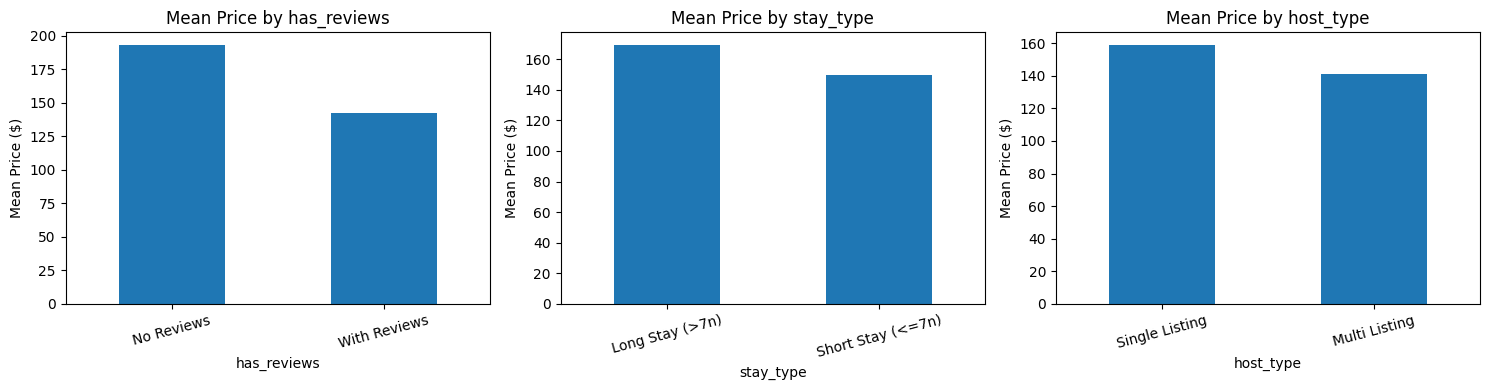

In [3]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. قراءة الملف الخام المرفوع في Colab
df = pd.read_csv('raw.csv')

# 2. التنظيف الأساسي وحفظ data/clean.csv
df_clean = df[df['price'] > 0].copy()
df_clean['reviews_per_month'] = df_clean['reviews_per_month'].fillna(0)
df_clean['name'] = df_clean['name'].fillna('غير محدد')
df_clean['host_name'] = df_clean['host_name'].fillna('غير محدد')

os.makedirs('data', exist_ok=True)
df_clean.to_csv('data/clean.csv', index=False)
print('تم إنشاء وحفظ data/clean.csv بنجاح:', df_clean.shape)

# 3. إنشاء 3 أعمدة جديدة (Feature Engineering)
df_clean['has_reviews'] = np.where(
    df_clean['number_of_reviews'] > 0, 'With Reviews', 'No Reviews'
)
df_clean['stay_type'] = np.where(
    df_clean['minimum_nights'] <= 7, 'Short Stay (<=7n)', 'Long Stay (>7n)'
)
df_clean['host_type'] = np.where(
    df_clean['calculated_host_listings_count'] == 1,
    'Single Listing',
    'Multi Listing',
)

features = ['has_reviews', 'stay_type', 'host_type']

for col in features:
  print(f'\n--- {col} vs price ---')
  print(
      df_clean.groupby(col)['price'].agg(
          count='count', mean='mean', median='median'
      )
  )

# 4. رسم علاقة الأعمدة الجديدة بمتوسط السعر
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, features):
  means = df_clean.groupby(col)['price'].mean().sort_values(ascending=False)
  means.plot(kind='bar', ax=ax)
  ax.set_title(f'Mean Price by {col}')
  ax.set_ylabel('Mean Price ($)')
  ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

هندسة الخصائص (Feature Engineering):

1. العمود الجديد: has_reviews (هل الإعلان عليه مراجعات أم لا؟)
- لماذا أضفته؟ لمعرفة ما إذا كان تسعير الإعلانات التي لم تحصل على مراجعات يختلف عن الإعلانات ذات المراجعات السابقة.
- علاقته بالسعر (برقم): الإعلانات بدون مراجعات (No Reviews، وعددها 10,051) يبلغ متوسط سعرها 192.94$ والوسيط 120.0$، مقابل متوسط 142.35$ والوسيط 101.0$ للإعلانات ذات المراجعات (With Reviews، وعددها 38,833).

2. العمود الجديد: stay_type (نوع الإقامة حسب الحد الأدنى لليالي)
- لماذا أضفته؟ لتمييز الإقامات القصيرة (7 ليالٍ أو أقل) عن الإقامات الأطول (أكثر من 7 ليالٍ) وفحص أثر مدة الإقامة على سعر الليلة.
- علاقته بالسعر (برقم): إقامات Long Stay (>7n) (وعددها 7,331) يبلغ متوسط سعرها 169.10$ والوسيط 120.0$، بينما إقامات Short Stay (<=7n) (وعددها 41,553) متوسط سعرها 149.87$ والوسيط 103.0$.

3. العمود الجديد: host_type (هل المضيف صاحب إعلان واحد أم عدة إعلانات؟)
- لماذا أضفته؟ لمعرفة الفارق في التسعير بين المضيفين الفرديين والمضيفين ذوي الإعلانات المتعددة.
- علاقته بالسعر (برقم): الإعلانات الفردية Single Listing (وعددها 32,301) يبلغ متوسط سعرها 158.69$ والوسيط 119.0$، مقابل متوسط 141.20$ والوسيط 93.0$ للإعلانات المتعددة Multi Listing (وعددها 16,583).

عدد الأعمدة قبل الحذف: 19
عدد الأعمدة بعد الحذف: 14
الأعمدة المحذوفة: ['id', 'host_id', 'name', 'host_name', 'last_review']

الأعمدة المتبقية في data/model_ready.csv:
['neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'has_reviews', 'stay_type', 'host_type']

معامل الارتباط مع السعر (price):
longitude                        -0.149954
reviews_per_month                -0.050531
number_of_reviews                -0.047926
latitude                          0.033899
minimum_nights                    0.042805
calculated_host_listings_count    0.057462
availability_365                  0.081847
Name: price, dtype: float64


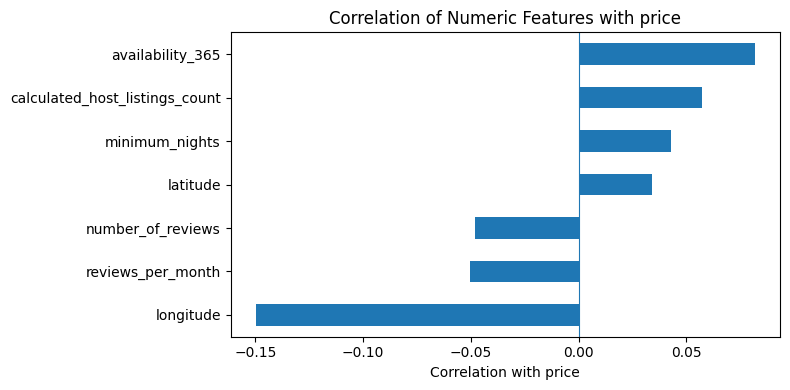

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. قراءة البيانات النظيفة
df_mr = pd.read_csv('data/clean.csv')

# إعادة إنشاء الأعمدة الثلاثة الجديدة للتأكد من وجودها في df_mr
df_mr['has_reviews'] = np.where(
    df_mr['number_of_reviews'] > 0, 'With Reviews', 'No Reviews'
)
df_mr['stay_type'] = np.where(
    df_mr['minimum_nights'] <= 7, 'Short Stay (<=7n)', 'Long Stay (>7n)'
)
df_mr['host_type'] = np.where(
    df_mr['calculated_host_listings_count'] == 1,
    'Single Listing',
    'Multi Listing',
)

# 2. تحديد الأعمدة المراد حذفها (معرفات، أسماء، وتاريخ آخر مراجعة)
cols_to_drop = ['id', 'host_id', 'name', 'host_name', 'last_review']
df_model_ready = df_mr.drop(columns=cols_to_drop).copy()

# حفظ الناتج في data/model_ready.csv
model_ready_path = 'data/model_ready.csv'
df_model_ready.to_csv(model_ready_path, index=False)

print('عدد الأعمدة قبل الحذف:', df_mr.shape[1])
print('عدد الأعمدة بعد الحذف:', df_model_ready.shape[1])
print('الأعمدة المحذوفة:', cols_to_drop)
print('\nالأعمدة المتبقية في data/model_ready.csv:')
print(list(df_model_ready.columns))

# 3. رسمة داعمة للقرار: ارتباط المتغيرات الرقمية مع السعر (price)
numeric_cols = df_model_ready.select_dtypes(include=[np.number]).columns
corr_with_price = (
    df_model_ready[numeric_cols]
    .corr()['price']
    .drop('price')
    .sort_values()
)

print('\nمعامل الارتباط مع السعر (price):')
print(corr_with_price)

plt.figure(figsize=(8, 4))
corr_with_price.plot(kind='barh')
plt.title('Correlation of Numeric Features with price')
plt.xlabel('Correlation with price')
plt.axvline(0, linewidth=0.8)
plt.tight_layout()
plt.show()

قرارات اختيار الخصائص (Feature Selection - القسم 7):
- الملف النهائي المحفوظ: data/model_ready.csv[span_1](start_span)[span_1](end_span)
- عدد الأعمدة: من 19 عموداً إلى 14 عموداً (حذف 5 أعمدة والاحتفاظ بـ 14 عموداً)[span_2](start_span)[span_2](end_span)

أولاً: الأعمدة المحذوفة (5 أعمدة)[span_3](start_span)[span_3](end_span):
1. id و host_id:
   - القرار: حذف.
   - السبب والرقم: معرفات رقمية لا تحمل دلالة تسعيرية (على 48,884 صفاً، و0 تكرارات في البيانات الخام).
2. name و host_name:
   - القرار: حذف.
   - السبب والرقم: أسماء ونصوص وصفية متغيرة لكل إعلان (كان فيهما 16 و 21 قيمة مفقودة في البيانات الخام).
3. last_review:
   - القرار: حذف.
   - السبب والرقم: تاريخ آخر مراجعة يكرر معلومة النشاط التي تم تغطيتها بعمود has_reviews و reviews_per_month (كان فيه 10,052 قيمة مفقودة في البيانات الخام).

ثانياً: الأعمدة المحتفَظ بها (14 عموداً)[span_4](start_span)[span_4](end_span):
- الهدف: price (المتغير المستهدف لتنبؤ سعر الليلة).
- الموقع ونوع الوحدة: neighbourhood_group، neighbourhood، latitude (معامل الارتباط مع السعر +0.033899)، longitude (معامل الارتباط مع السعر -0.149954 وهو الأقوى عكسياً بين المتغيرات الرقمية المرسومة)، room_type[span_5](start_span)[span_5](end_span).
- النشاط والإتاحة والمضيف: availability_365 (معامل الارتباط +0.081847 وهو الأعلى طردياً بين المتغيرات الرقمية المرسومة)، calculated_host_listings_count (معامل الارتباط +0.057462)، minimum_nights (معامل الارتباط +0.042805)، number_of_reviews (معامل الارتباط -0.047926)، reviews_per_month (معامل الارتباط -0.050531)[span_6](start_span)[span_6](end_span).
- الأعمدة الجديدة (Feature Engineering): has_reviews، stay_type، host_type (لأنها أظهرت فروقاً واضحة في متوسط ووسيط السعر).